# Dados e Aprendizagem Automática 26/27
### Part IX

## **K-means, K-medoids and DBSCAN using College_Data Dataset - Ficha**

### The data
777 observations, 18 variables:

* **Private** - A factor with levels No and Yes indicating private or public university
* **Apps** - Number of applications received
* **Accept** - Number of applications accepted
* **Enroll** - Number of new students enrolled
* **Top10perc** - % of new students from top 10% of H.S. class
* **Top25perc** - % of new students from top 25% of H.S. class
* **F.Undergrad** - Number of full-time undergraduates
* **P.Undergrad** - Number of part-time undergraduates
* **Outstate** - Out-of-state tuition
* **Room.Board** - Room and board costs
* **Books** - Estimated book costs
* **Personal** - Estimated personal spending
* **PhD** - % of faculty with Ph.D.’s
* **Terminal** - % of faculty with terminal degree
* **S.F.Ratio** - Student/faculty ratio
* **perc.alumni** - % of alumni who donate
* **Expend** - Instructional expenditure per student
* **Grad.Rate** - Graduation rate

### Imports

In [18]:
import sklearn as skl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, DBSCAN
from sklearn_extra.cluster import KMedoids
from sklearn import metrics
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.neighbors import NearestNeighbors

%matplotlib inline

### Load and inspect the data

In [19]:
df = pd.read_csv('../daa_datasets_pl9/College_Data', index_col=0)   # se o ficheiro tiver extensão: 'College_Data.csv'

In [20]:
df.head()

,Private,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
Abilene Christian University,Yes,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70,78,18.1,12,7041,60
Adelphi University,Yes,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29,30,12.2,16,10527,56
Adrian College,Yes,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53,66,12.9,30,8735,54
Agnes Scott College,Yes,417,349,137,60,89,510,63,12960,5450,450,875,92,97,7.7,37,19016,59
Alaska Pacific University,Yes,193,146,55,16,44,249,869,7560,4120,800,1500,76,72,11.9,2,10922,15


In [21]:
df.info()

<class 'pandas.DataFrame'>
Index: 777 entries, Abilene Christian University to York College of Pennsylvania
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Private      777 non-null    str    
 1   Apps         777 non-null    int64  
 2   Accept       777 non-null    int64  
 3   Enroll       777 non-null    int64  
 4   Top10perc    777 non-null    int64  
 5   Top25perc    777 non-null    int64  
 6   F.Undergrad  777 non-null    int64  
 7   P.Undergrad  777 non-null    int64  
 8   Outstate     777 non-null    int64  
 9   Room.Board   777 non-null    int64  
 10  Books        777 non-null    int64  
 11  Personal     777 non-null    int64  
 12  PhD          777 non-null    int64  
 13  Terminal     777 non-null    int64  
 14  S.F.Ratio    777 non-null    float64
 15  perc.alumni  777 non-null    int64  
 16  Expend       777 non-null    int64  
 17  Grad.Rate    777 non-null    int64  
dtypes: float64(1),

In [22]:
df.describe()

,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
count,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.00000
mean,3001.638353,2018.804376,779.972973,27.558559,55.796654,3699.907336,855.298584,10440.669241,4357.526384,549.380952,1340.642214,72.660232,79.702703,14.089704,22.743887,9660.171171,65.46332
std,3870.201484,2451.113971,929.176190,17.640364,19.804778,4850.420531,1522.431887,4023.016484,1096.696416,165.105360,677.071454,16.328155,14.722359,3.958349,12.391801,5221.768440,17.17771
min,81.000000,72.000000,35.000000,1.000000,9.000000,139.000000,1.000000,2340.000000,1780.000000,96.000000,250.000000,8.000000,24.000000,2.500000,0.000000,3186.000000,10.00000
25%,776.000000,604.000000,242.000000,15.000000,41.000000,992.000000,95.000000,7320.000000,3597.000000,470.000000,850.000000,62.000000,71.000000,11.500000,13.000000,6751.000000,53.00000
50%,1558.000000,1110.000000,434.000000,23.000000,54.000000,1707.000000,353.000000,9990.000000,4200.000000,500.000000,1200.000000,75.000000,82.000000,13.600000,21.000000,8377.000000,65.00000
75%,3624.000000,2424.000000,902.000000,35.000000,69.000000,4005.000000,967.000000,12925.000000,5050.000000,600.000000,1700.000000,85.000000,92.000000,16.500000,31.000000,10830.000000,78.00000
max,48094.000000,26330.000000,6392.000000,96.000000,100.000000,31643.000000,21836.000000,21700.000000,8124.000000,2340.000000,6800.000000,103.000000,100.000000,39.800000,64.000000,56233.000000,118.00000


### EDA

Create a scatterplot of <em>Grad.Rate</em> vs. <em>Room.Board</em> where the points are grouped by the <em>Private</em> column:

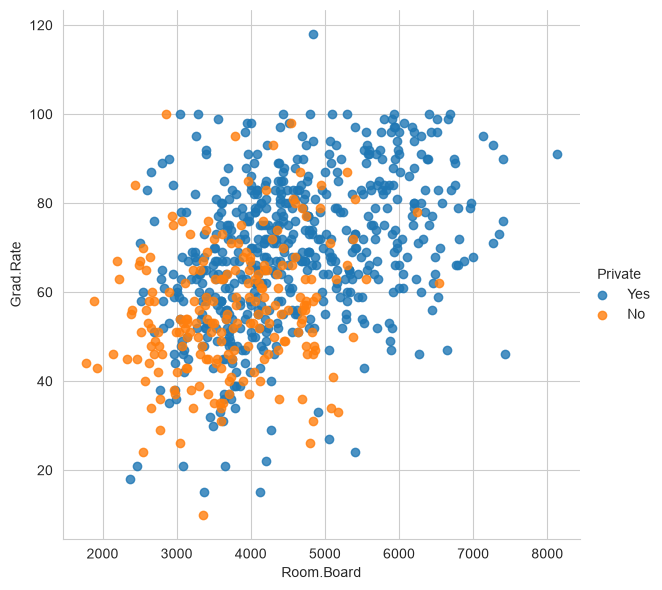

In [23]:
sns.set_style('whitegrid')
sns.lmplot(x = 'Room.Board', y = 'Grad.Rate', data = df, hue = 'Private', height = 6, aspect = 1, fit_reg = False)

Create a scatterplot of <em>F.Undergrad</em> vs. <em>Outstate</em> where the points are grouped by the <em>Private</em> column:

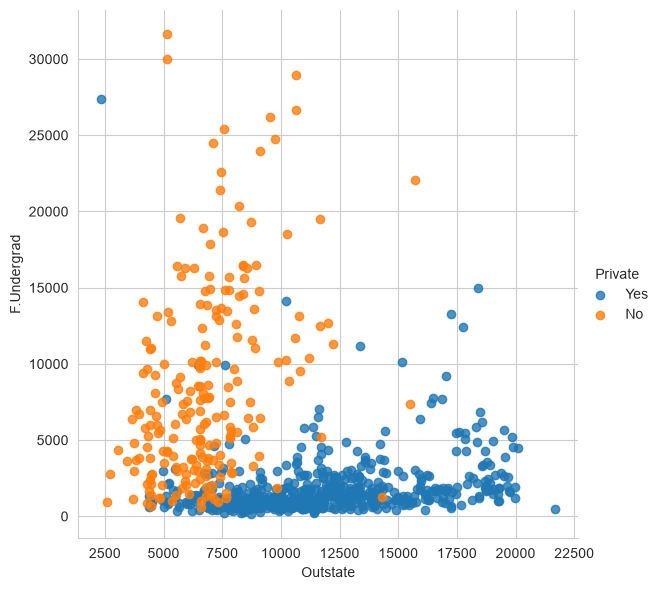

In [24]:
sns.set_style('whitegrid')
sns.lmplot(x = 'Outstate', y = 'F.Undergrad', data = df, hue = 'Private', height = 6, aspect = 1, fit_reg = False)

Create a stacked histogram showing <em>Out of State Tuition</em> based on the <em>Private</em> column.  
Try doing this using [sns.FacetGrid](https://stanford.edu/~mwaskom/software/seaborn/generated/seaborn.FacetGrid.html). <ins>Alternative</ins>: you can do it by using two instances of <code>pandas.plot(kind='hist')</code>:

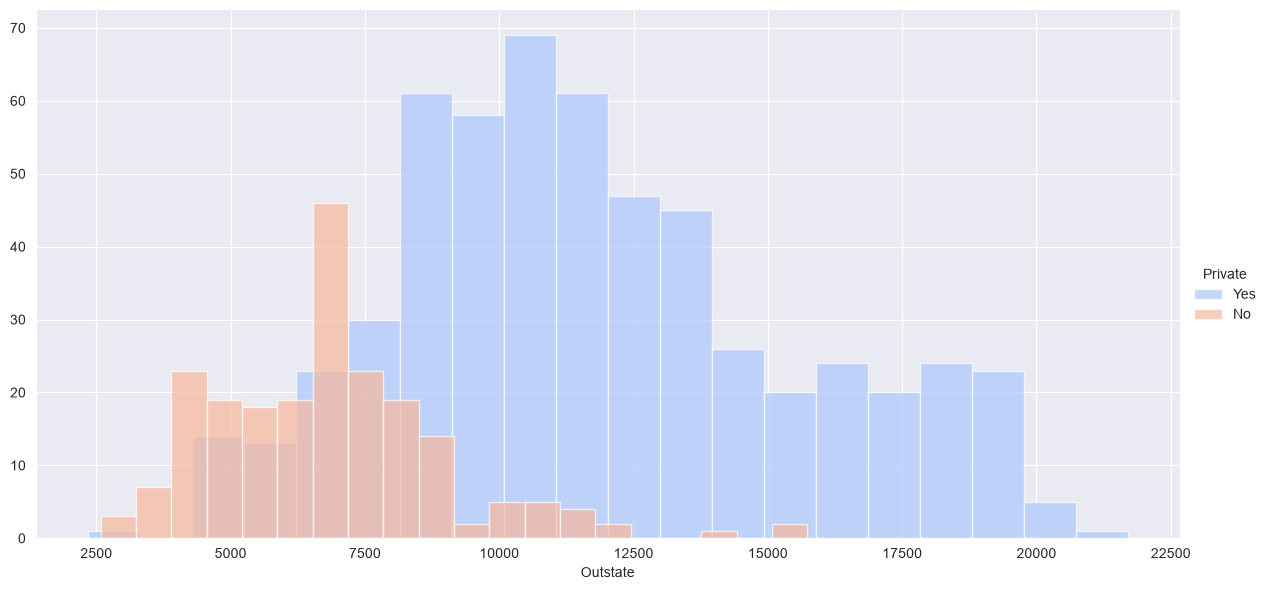

In [25]:
sns.set_style('darkgrid')
g = sns.FacetGrid(df, hue = 'Private', palette = 'coolwarm', height = 6, aspect = 2)
g = g.map(plt.hist, 'Outstate', bins = 20, alpha = 0.7)
g.add_legend()

Create a similar histogram for the <em>Grad.Rate</em> column:

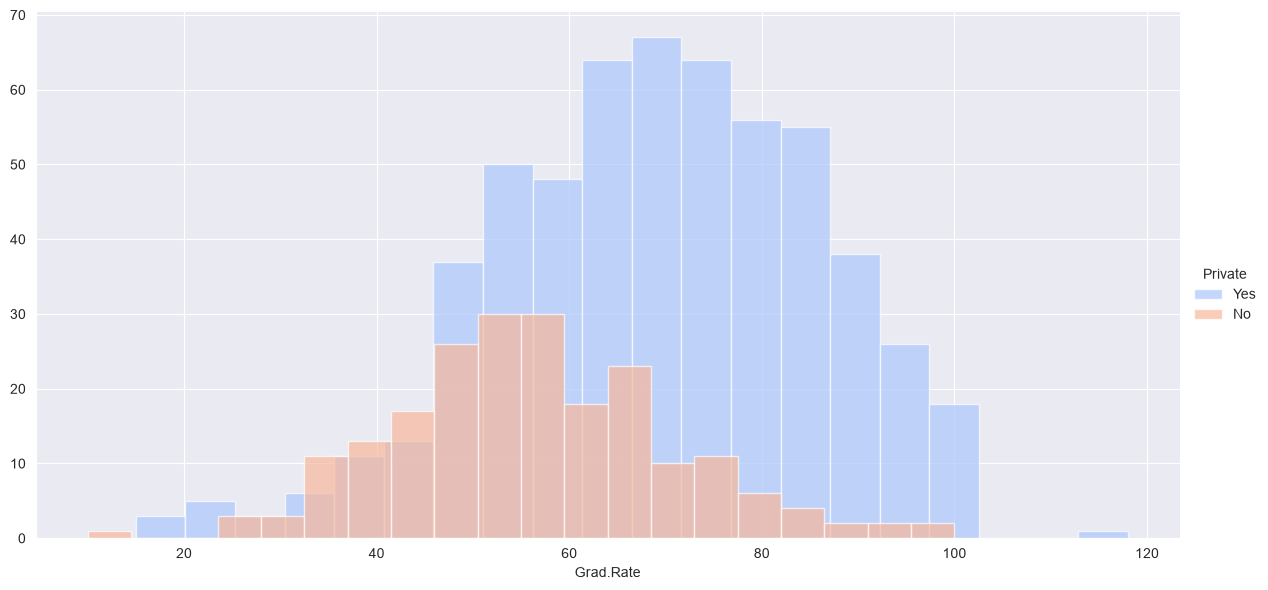

In [26]:
sns.set_style('darkgrid')
g = sns.FacetGrid(df, hue = 'Private', palette = 'coolwarm', height = 6, aspect = 2)
g = g.map(plt.hist,'Grad.Rate', bins = 20, alpha = 0.7)
g.add_legend()

Notice that there seems to be a private school with a graduation rate of higher than 100%. **What is the name of that school?**

In [27]:
df[df['Grad.Rate'] > 100]

,Private,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
Cazenovia College,Yes,3847,3433,527,9,35,1010,12,9384,4840,600,500,22,47,14.3,20,7697,118


Set that school's graduation rate to 100. You may get a warning (not an error) when doing this operation, so use dataframe operations or just re-do the histogram visualization to make sure it actually went through:

In [28]:
df.loc['Cazenovia College', 'Grad.Rate'] = 100

In [29]:
df[df['Grad.Rate'] > 100]

,Private,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate


In [30]:
df[df['Grad.Rate'] == 100].loc[['Cazenovia College']]

,Private,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
Cazenovia College,Yes,3847,3433,527,9,35,1010,12,9384,4840,600,500,22,47,14.3,20,7697,100


Re-create the histogram for the <em>Grad.Rate</em> column:

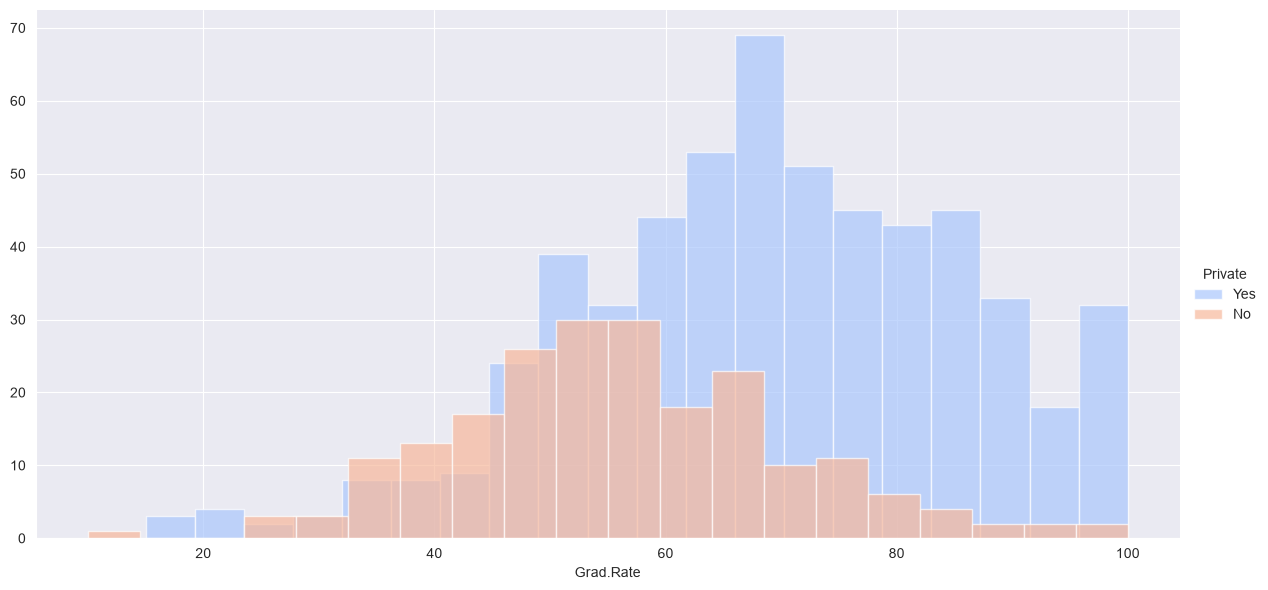

In [31]:
sns.set_style('darkgrid')
g = sns.FacetGrid(df, hue = 'Private', palette = 'coolwarm', height = 6, aspect = 2)
g = g.map(plt.hist,'Grad.Rate', bins = 20, alpha = 0.7)
g.add_legend()

Let's convert feature *Private* to numeric

In [32]:
def convert(data):
    if data == 'Yes':
        return 0
    else:
        return 1

df['Private2'] = df['Private'].apply(convert)

In [33]:
df.head()

,Private,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate,Private2
Abilene Christian University,Yes,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70,78,18.1,12,7041,60,0
Adelphi University,Yes,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29,30,12.2,16,10527,56,0
Adrian College,Yes,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53,66,12.9,30,8735,54,0
Agnes Scott College,Yes,417,349,137,60,89,510,63,12960,5450,450,875,92,97,7.7,37,19016,59,0
Alaska Pacific University,Yes,193,146,55,16,44,249,869,7560,4120,800,1500,76,72,11.9,2,10922,15,0


Defining X and y

In [34]:
X = df.drop(columns=['Private', 'Private2'])
y = df['Private2']

In [35]:
X.head()

,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
Abilene Christian University,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70,78,18.1,12,7041,60
Adelphi University,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29,30,12.2,16,10527,56
Adrian College,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53,66,12.9,30,8735,54
Agnes Scott College,417,349,137,60,89,510,63,12960,5450,450,875,92,97,7.7,37,19016,59
Alaska Pacific University,193,146,55,16,44,249,869,7560,4120,800,1500,76,72,11.9,2,10922,15


In [36]:
y.head()

Abilene Christian University    0
Adelphi University              0
Adrian College                  0
Agnes Scott College             0
Alaska Pacific University       0
Name: Private2, dtype: int64

In [37]:
y.value_counts()

Private2
0    565
1    212
Name: count, dtype: int64

In [38]:
print(X.shape, y.shape)

(777, 17) (777,)


Creating the visualizations again

Text(0, 0.5, 'Grad.Rate')

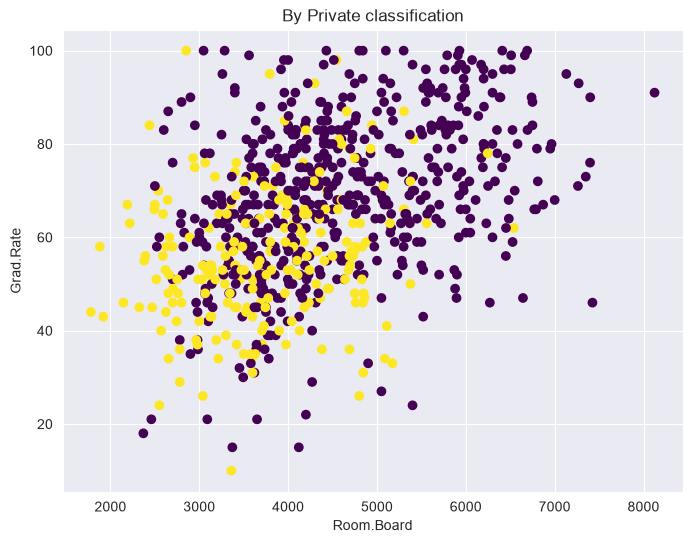

In [39]:
plt.figure(figsize=(8, 6))
plt.scatter(X['Room.Board'], X['Grad.Rate'], c = y, cmap = 'viridis')
plt.title('By Private classification')
plt.xlabel('Room.Board')
plt.ylabel('Grad.Rate')

Text(0, 0.5, 'F.Undergrad')

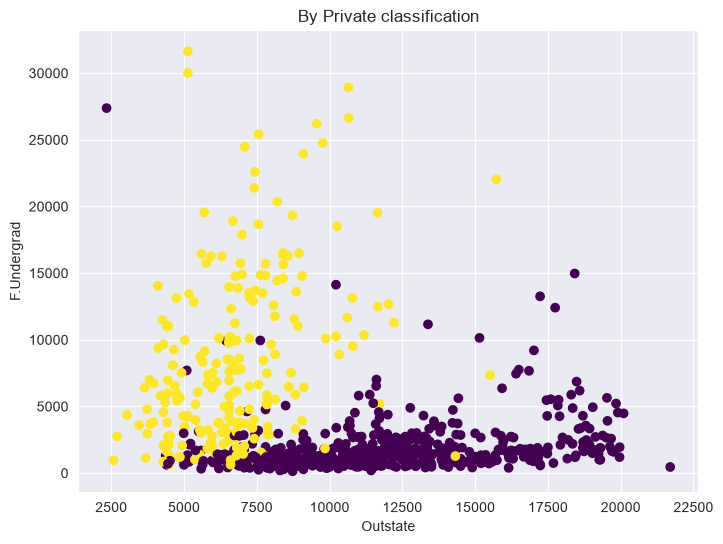

In [40]:
plt.figure(figsize=(8, 6))
plt.scatter(X['Outstate'], X['F.Undergrad'], c = y, cmap = 'viridis')
plt.title('By Private classification')
plt.xlabel('Outstate')
plt.ylabel('F.Undergrad')

### Clustering

#### K-Means

K-Means with 2 clusters

In [41]:
kmeans = KMeans(n_clusters = 2, n_init = 10, random_state = 2022)

In [42]:
kmeans.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",2022
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 17)","[[

Cluster center vectors

In [43]:
kmeans.cluster_centers_

array([[1.81323468e+03, 1.28716592e+03, 4.91044843e+02, 2.53094170e+01,
        5.34708520e+01, 2.18854858e+03, 5.95458894e+02, 1.03957085e+04,
        4.31136472e+03, 5.41982063e+02, 1.28033632e+03, 7.04424514e+01,
        7.78251121e+01, 1.40997010e+01, 2.31748879e+01, 8.93204634e+03,
        6.50926756e+01],
       [1.03631389e+04, 6.55089815e+03, 2.56972222e+03, 4.14907407e+01,
        7.02037037e+01, 1.30619352e+04, 2.46486111e+03, 1.07191759e+04,
        4.64347222e+03, 5.95212963e+02, 1.71420370e+03, 8.63981481e+01,
        9.13333333e+01, 1.40277778e+01, 2.00740741e+01, 1.41705000e+04,
        6.75925926e+01]])

##### Evaluation

There is no perfect way to evaluate the clustering if you don't have the labels. However, we do have the labels, but as this is an exercise, we will use them to evaluate our clusters.  
<ins>Keep in mind</ins>: you usually won't have this privilege in the real world.

In [44]:
labels_means = kmeans.labels_
labels_means

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [45]:
# os nº dos clusters são arbitrários: alinhar com Private2 (0 = privada, 1 = pública)
if (labels_means == df['Private2'].values).mean() < 0.5:
    labels_means = 1 - labels_means
labels_means

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [46]:
df_means = df.copy()

In [47]:
df_means.insert(1, "Labels.Means", labels_means, True)

In [48]:
df_means.head()

,Private,Labels.Means,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate,Private2
Abilene Christian University,Yes,0,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70,78,18.1,12,7041,60,0
Adelphi University,Yes,0,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29,30,12.2,16,10527,56,0
Adrian College,Yes,0,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53,66,12.9,30,8735,54,0
Agnes Scott College,Yes,0,417,349,137,60,89,510,63,12960,5450,450,875,92,97,7.7,37,19016,59,0
Alaska Pacific University,Yes,0,193,146,55,16,44,249,869,7560,4120,800,1500,76,72,11.9,2,10922,15,0


Create a histogram of the clusters grouped by <em>Private2</em> column:

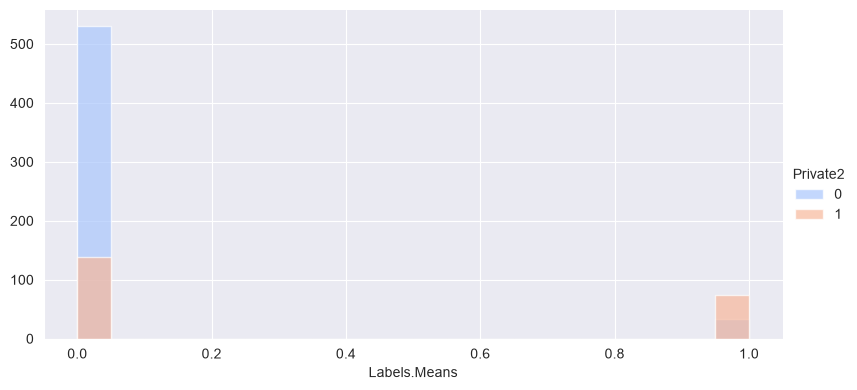

In [49]:
sns.set_style('darkgrid')
g = sns.FacetGrid(df_means, hue = 'Private2', palette = 'coolwarm', height = 4, aspect = 2)
g = g.map(plt.hist, 'Labels.Means', bins = 20, alpha = 0.7)
g.add_legend()

Create a lmplot of the clusters vs. <em>F.Undergrad</em> grouped by <em>Private</em> column:

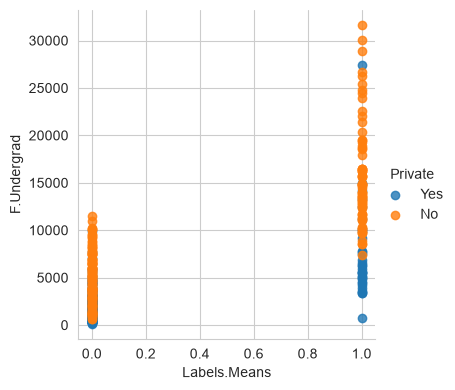

In [50]:
sns.set_style('whitegrid')
sns.lmplot(x = 'Labels.Means', y = 'F.Undergrad', data = df_means, hue = 'Private', height = 4, aspect = 1, fit_reg = False)

Create a confusion matrix, classification report and other metrics approached in class to see how well the K-Means clustering worked without being given any labels:

In [51]:
print(confusion_matrix(df['Private2'], labels_means))

[[531  34]
 [138  74]]


In [52]:
print(classification_report(df['Private2'], labels_means))

              precision    recall  f1-score   support

           0       0.79      0.94      0.86       565
           1       0.69      0.35      0.46       212

    accuracy                           0.78       777
   macro avg       0.74      0.64      0.66       777
weighted avg       0.76      0.78      0.75       777



In [53]:
print(f"Homogeneity: {metrics.homogeneity_score(df['Private2'], labels_means):.3f}")
print(f"Completeness: {metrics.completeness_score(df['Private2'], labels_means):.3f}")
print(f"V-measure: {metrics.v_measure_score(df['Private2'], labels_means):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(df['Private2'], labels_means):.3f}")
print(f"Adjusted Mutual Information: {metrics.adjusted_mutual_info_score(df['Private2'], labels_means):.3f}")
print(f"Silhouette Coefficient: {metrics.silhouette_score(X, labels_means):.3f}")

Homogeneity: 0.105
Completeness: 0.152
V-measure: 0.124
Adjusted Rand Index: 0.227
Adjusted Mutual Information: 0.123
Silhouette Coefficient: 0.560


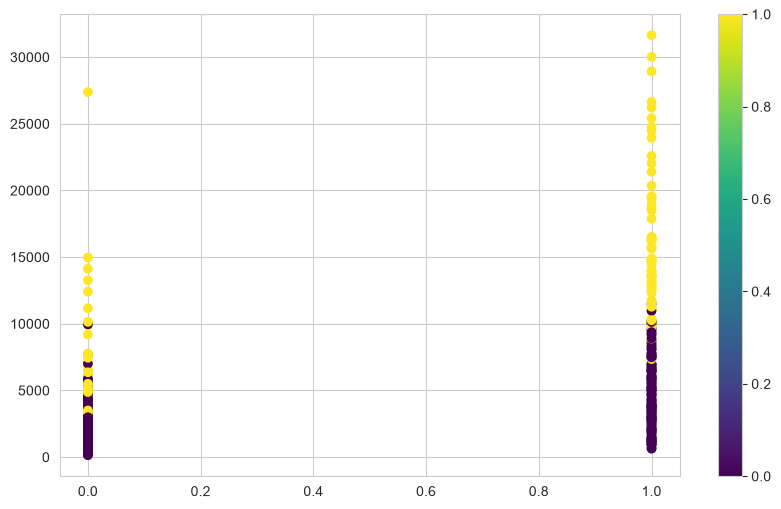

In [54]:
plt.figure(figsize=(10, 6))
scatter = plt.scatter(df_means['Private2'], df_means['F.Undergrad'], c=df_means['Labels.Means'], cmap='viridis')
plt.colorbar(scatter)

It is not so bad considering that the algorithm is only using the features to cluster the universities into two distinct groups! Hopefully, you can start to see how useful K-Means is for clustering unlabelled data!

#### K-Medoids

K-Medoids with 2 clusters

In [55]:
kmedoids = KMedoids(n_clusters = 2, random_state = 2022)

In [56]:
kmedoids.fit(X)

,n_clusters,2
,random_state,2022
,metric,'euclidean'
,method,'alternate'
,init,'heuristic'
,max_iter,300
Name,Type,Value
cluster_centers_,"ndarray[float64](2, 17)","[[ 1660., 1232., 721.,..., 12., 7041., 60.], [ 1183., 1016., 411.,..., 20.,10368., 66.]]"
inertia_,float64,4.957e+06
labels_,"ndarray[int64](777,)","[0,1,1,...,0,1,0]"
medoid_indices_,"ndarray[int64](2,)","[ 0,516]"


Cluster center vectors

In [57]:
kmedoids.cluster_centers_

array([[1.6600e+03, 1.2320e+03, 7.2100e+02, 2.3000e+01, 5.2000e+01,
        2.8850e+03, 5.3700e+02, 7.4400e+03, 3.3000e+03, 4.5000e+02,
        2.2000e+03, 7.0000e+01, 7.8000e+01, 1.8100e+01, 1.2000e+01,
        7.0410e+03, 6.0000e+01],
       [1.1830e+03, 1.0160e+03, 4.1100e+02, 4.2000e+01, 8.2000e+01,
        1.9220e+03, 7.0400e+02, 1.2669e+04, 4.8750e+03, 6.0000e+02,
        1.2500e+03, 8.3000e+01, 8.5000e+01, 1.6800e+01, 2.0000e+01,
        1.0368e+04, 6.6000e+01]])

##### Evaluation

In [58]:
labels_med = kmedoids.labels_
# os nº dos clusters são arbitrários: alinhar com Private2 (0 = privada, 1 = pública)
if (labels_med == df['Private2'].values).mean() < 0.5:
    labels_med = 1 - labels_med
labels_med

array([1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1,
       0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1,
       1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0,
       0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0,
       0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1,
       1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0,
       1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1,
       1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0,
       1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0,
       1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1,
       1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1,

In [59]:
labels_med.shape

(777,)

In [60]:
df_med = df.copy()

In [61]:
df_med.insert(1, "Labels.Med", labels_med, True)

In [62]:
df_med.head()

,Private,Labels.Med,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate,Private2
Abilene Christian University,Yes,1,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70,78,18.1,12,7041,60,0
Adelphi University,Yes,0,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29,30,12.2,16,10527,56,0
Adrian College,Yes,0,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53,66,12.9,30,8735,54,0
Agnes Scott College,Yes,0,417,349,137,60,89,510,63,12960,5450,450,875,92,97,7.7,37,19016,59,0
Alaska Pacific University,Yes,1,193,146,55,16,44,249,869,7560,4120,800,1500,76,72,11.9,2,10922,15,0


Create a histogram of the clusters grouped by <em>Private2</em> column:

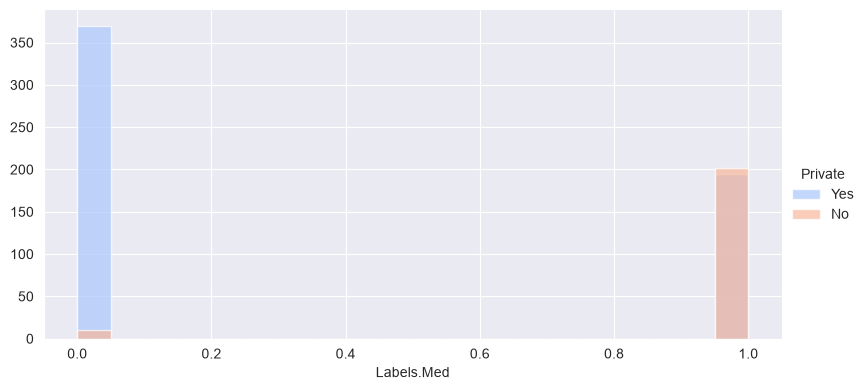

In [63]:
sns.set_style('darkgrid')
g = sns.FacetGrid(df_med, hue = "Private", palette = 'coolwarm', height = 4, aspect = 2)
g = g.map(plt.hist, 'Labels.Med', bins = 20, alpha = 0.7)
g.add_legend()

Create a lmplot of the clusters vs. <em>F.Undergrad</em> grouped by <em>Private</em> column:

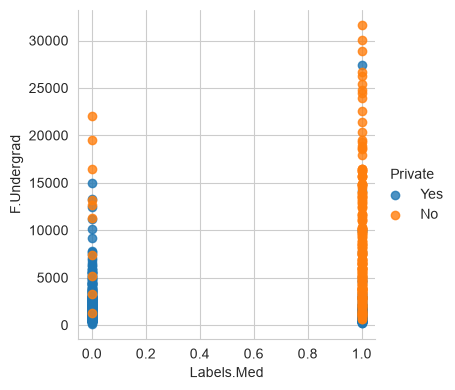

In [64]:
sns.set_style('whitegrid')
sns.lmplot(x = 'Labels.Med', y = 'F.Undergrad', data = df_med, hue = 'Private', height = 4, aspect = 1, fit_reg = False)

Analyze the metrics to see how well the K-Means clustering worked without being given any labels:

In [65]:
print(confusion_matrix(df['Private2'], labels_med))

[[370 195]
 [ 10 202]]


In [66]:
print(classification_report(df['Private2'], labels_med))

              precision    recall  f1-score   support

           0       0.97      0.65      0.78       565
           1       0.51      0.95      0.66       212

    accuracy                           0.74       777
   macro avg       0.74      0.80      0.72       777
weighted avg       0.85      0.74      0.75       777



In [67]:
print(f"Homogeneity: {metrics.homogeneity_score(df['Private2'], labels_med):.3f}")
print(f"Completeness: {metrics.completeness_score(df['Private2'], labels_med):.3f}")
print(f"V-measure: {metrics.v_measure_score(df['Private2'], labels_med):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(df['Private2'], labels_med):.3f}")
print(f"Adjusted Mutual Information: {metrics.adjusted_mutual_info_score(df['Private2'], labels_med):.3f}")
print(f"Silhouette Coefficient: {metrics.silhouette_score(X, labels_med):.3f}")

Homogeneity: 0.294
Completeness: 0.249
V-measure: 0.270
Adjusted Rand Index: 0.222
Adjusted Mutual Information: 0.269
Silhouette Coefficient: 0.259


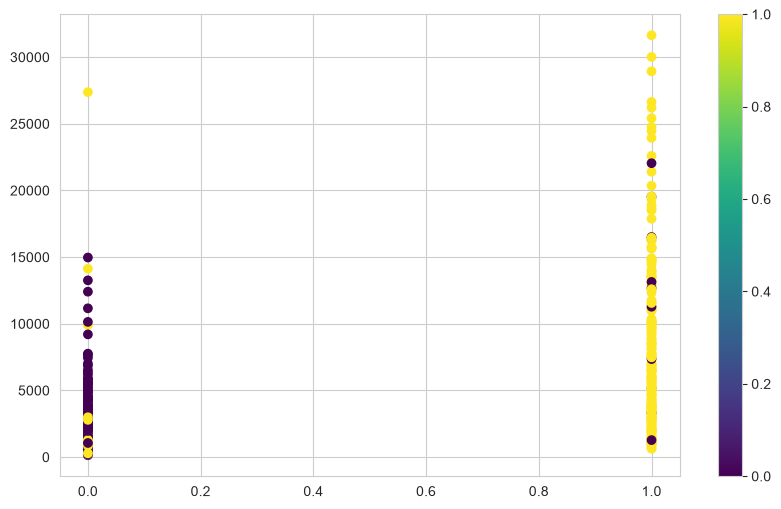

In [68]:
plt.figure(figsize=(10, 6))
scatter = plt.scatter(df_med['Private2'], df_med['F.Undergrad'], c=df_med['Labels.Med'], cmap='viridis')
plt.colorbar(scatter)

### DSCAN

Determine the $\epsilon$ parameter

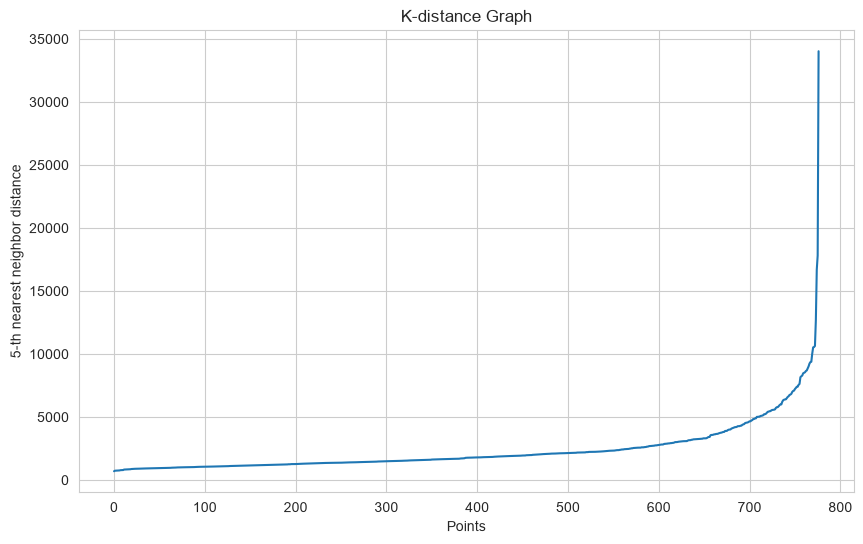

In [69]:
def plot_k_distance_graph(X, k):
    neigh = NearestNeighbors(n_neighbors=k)
    neigh.fit(X)
    distances, _ = neigh.kneighbors(X)
    distances = np.sort(distances[:, k-1])
    plt.figure(figsize=(10, 6))
    plt.plot(distances)
    plt.xlabel('Points')
    plt.ylabel(f'{k}-th nearest neighbor distance')
    plt.title('K-distance Graph')

plot_k_distance_graph(X, k=5)

In [70]:
# eps escolhido no 'cotovelo' do k-distance graph (os dados não estão normalizados: distâncias na ordem dos milhares)
# -> confirmar/ajustar depois de ver o gráfico acima
db = DBSCAN(eps=2500, min_samples=5)

In [71]:
db.fit(X)

,"eps eps: float, default=0.5The maximum distance between two samples for one to be consideredas in the neighborhood of the other. This is not a maximum boundon the distances of points within a cluster. This is the mostimportant DBSCAN parameter to choose appropriately for your data setand distance function. Smaller values generally lead to more clusters.",2500
,"min_samples min_samples: int, default=5The number of samples (or total weight) in a neighborhood for a point tobe considered as a core point. This includes the point itself. If`min_samples` is set to a higher value, DBSCAN will find denser clusters,whereas if it is set to a lower value, the found clusters will be moresparse.",5
,"metric metric: str, or callable, default='euclidean'The metric to use when calculating distance between instances in afeature array. If metric is a string or callable, it must be one ofthe options allowed by :func:`sklearn.metrics.pairwise_distances` forits metric parameter.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors for DBSCAN... versionadded:: 0.17 metric *precomputed* to accept precomputed sparse matrix.",'euclidean'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function... versionadded:: 0.19",None
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'The algorithm to be used by the NearestNeighbors moduleto compute pointwise distances and find nearest neighbors.'auto' will attempt to decide the most appropriate algorithmbased on the values passed to :meth:`fit` method.See :class:`~sklearn.neighbors.NearestNeighbors` documentation fordetails.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or cKDTree. This can affect the speedof the construction and query, as well as the memory requiredto store the tree. The optimal value dependson the nature of the problem.",30
,"p p: float, default=NoneThe power of the Minkowski metric to be used to calculate distancebetween points. If None, then ``p=2`` (equivalent to the Euclideandistance). When p=1, this is equivalent to Manhattan distance.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
"components_ components_: ndarray of shape (n_core_samples, n_features)Copy of each core sample found by training.","ndarray[float64](569, 17)","[[ 1660., 1232., 721.,..., 12., 7041., 60.], [ 2186., 1924., 512.,..., 16.,10527., 56.], [ 1428., 1097., 336.,..., 30., 8735., 54.], ..., [ 1959., 1805., 695.,..., 31., 9189., 83.], [ 2097., 1915., 695.,..., 20., 8323., 49.], [ 2989., 1855., 691.,..., 28., 4509., 99.]]"
"core_sample_indices_ core_sample_indices_: ndarray of shape (n_core_samples,)Indices of core samples.","ndarray[int64](569,)","[ 0, 1, 2,...,773,774,776]"


Confirm the associated labels shape

In [72]:
labels_db = db.labels_
labels_db

array([ 0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  1,
        0,  0,  0, -1,  0,  0, -1, -1,  0,  0, -1,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0, -1,  1, -1,  0, -1,  0,  0,  0,  0,
        0, -1, -1,  0, -1,  0,  0,  0,  0,  0, -1, -1,  0,  0,  0,  0,  0,
        0,  0, -1,  0,  0,  0, -1,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,
       -1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0, -1,  0,  0, -1, -1,  0, -1,  0,  0,  0,  0,  0,  0,  0, -1,
        0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0, -1,  0, -1, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0, -1,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1,  0, -1,
        0,  0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0, -1, -1,  0,
       -1, -1, -1,  0,  0

In [73]:
np.unique(labels_db, return_counts=True)

(array([-1,  0,  1]), array([166, 605,   6]))

Number of clusters in *labels* (ignoring noise if present)

In [74]:
n_clusters_ = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_noise_ = list(labels_db).count(-1)

In [75]:
print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)

Estimated number of clusters: 2
Estimated number of noise points: 166


Obtain predictions

In [76]:
pred = db.fit_predict(X)

In [77]:
pred

array([ 0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  1,
        0,  0,  0, -1,  0,  0, -1, -1,  0,  0, -1,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0, -1,  1, -1,  0, -1,  0,  0,  0,  0,
        0, -1, -1,  0, -1,  0,  0,  0,  0,  0, -1, -1,  0,  0,  0,  0,  0,
        0,  0, -1,  0,  0,  0, -1,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,
       -1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0, -1,  0,  0, -1, -1,  0, -1,  0,  0,  0,  0,  0,  0,  0, -1,
        0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0, -1,  0, -1, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0, -1,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1,  0, -1,
        0,  0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0, -1, -1,  0,
       -1, -1, -1,  0,  0

In [78]:
(pred==labels_db).all()

np.True_

In [79]:
pred = np.where(pred==-1, 1, pred)


In [80]:
pred

array([0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0,
       0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [81]:
labels_db = np.where(labels_db==-1, 1, labels_db)


In [82]:
df_db = df.copy()

In [83]:
df_db.insert(1, "Labels.DBSCAN", labels_db, True)

In [84]:
df_db.head()

,Private,Labels.DBSCAN,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate,Private2
Abilene Christian University,Yes,0,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70,78,18.1,12,7041,60,0
Adelphi University,Yes,0,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29,30,12.2,16,10527,56,0
Adrian College,Yes,0,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53,66,12.9,30,8735,54,0
Agnes Scott College,Yes,1,417,349,137,60,89,510,63,12960,5450,450,875,92,97,7.7,37,19016,59,0
Alaska Pacific University,Yes,0,193,146,55,16,44,249,869,7560,4120,800,1500,76,72,11.9,2,10922,15,0


Create a histogram of the clusters grouped by <em>Private2</em> column:

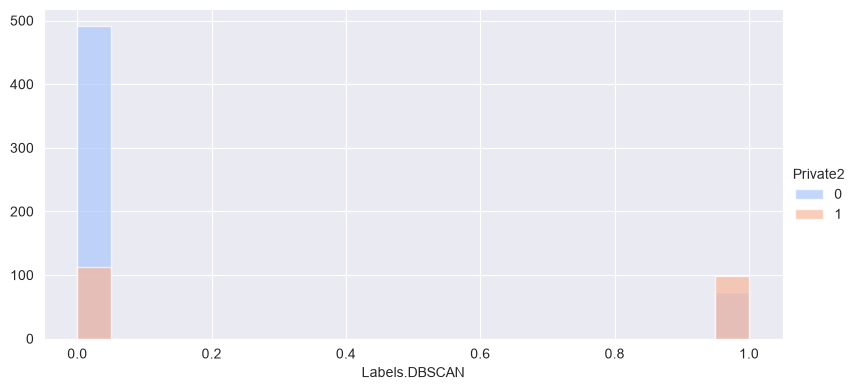

In [85]:
sns.set_style('darkgrid')
g = sns.FacetGrid(df_db, hue = 'Private2', palette = 'coolwarm', height = 4, aspect = 2)
g = g.map(plt.hist, 'Labels.DBSCAN', bins = 20, alpha = 0.7)
g.add_legend()

Create a lmplot of the clusters vs. <em>F.Undergrad</em> grouped by <em>Private</em> column:

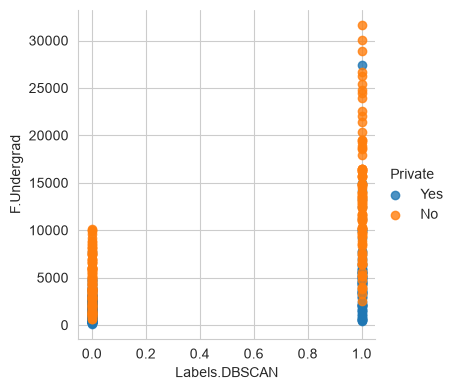

In [86]:
sns.set_style('whitegrid')
sns.lmplot(x = 'Labels.DBSCAN', y = 'F.Undergrad', data = df_db, hue = 'Private', height = 4, aspect = 1, fit_reg = False)

Analyze throught the metrics to see how well the K-Means clustering worked without being given any labels:

In [87]:
print(confusion_matrix(df['Private2'], labels_db))

[[492  73]
 [113  99]]


In [88]:
print(classification_report(df['Private2'], labels_db, zero_division=0))

              precision    recall  f1-score   support

           0       0.81      0.87      0.84       565
           1       0.58      0.47      0.52       212

    accuracy                           0.76       777
   macro avg       0.69      0.67      0.68       777
weighted avg       0.75      0.76      0.75       777



In [89]:
print(f"Homogeneity: {metrics.homogeneity_score(df['Private2'], labels_db):.3f}")
print(f"Completeness: {metrics.completeness_score(df['Private2'], labels_db):.3f}")
print(f"V-measure: {metrics.v_measure_score(df['Private2'], labels_db):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(df['Private2'], labels_db):.3f}")
print(f"Adjusted Mutual Information: {metrics.adjusted_mutual_info_score(df['Private2'], labels_db):.3f}")
print(f"Silhouette Coefficient: {metrics.silhouette_score(X, labels_db):.3f}")

Homogeneity: 0.103
Completeness: 0.114
V-measure: 0.108
Adjusted Rand Index: 0.221
Adjusted Mutual Information: 0.107
Silhouette Coefficient: 0.449


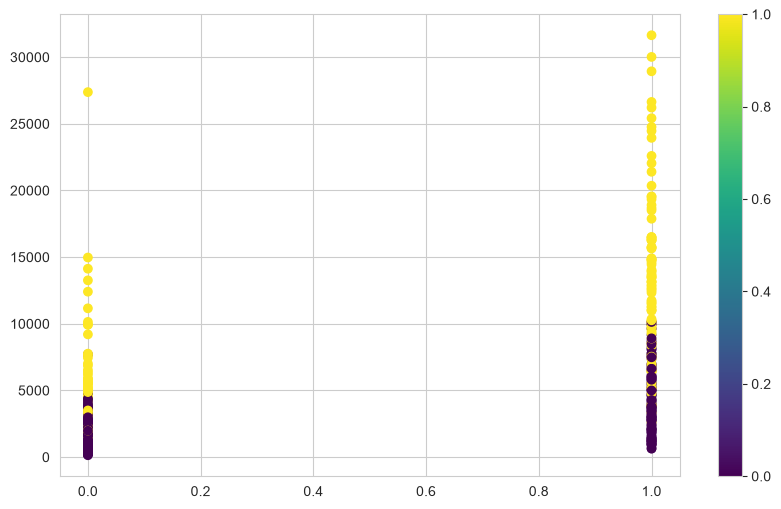

In [90]:
plt.figure(figsize=(10, 6))
scatter = plt.scatter(df_db['Private2'], df_db['F.Undergrad'], c=df_db['Labels.DBSCAN'], cmap='viridis')
plt.colorbar(scatter)

### Comparing DBSCAN and K-Means

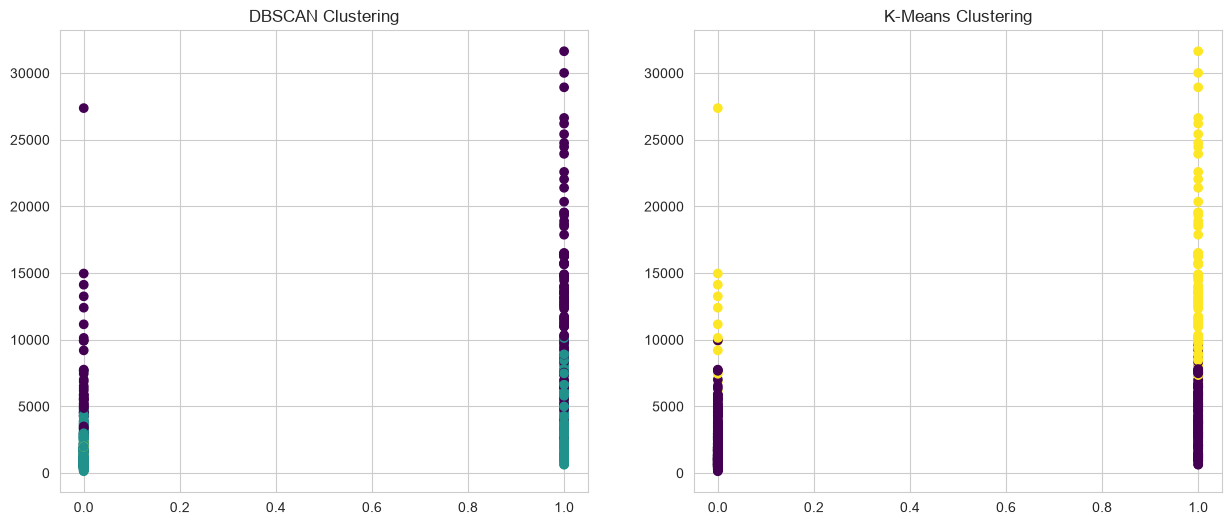

In [91]:
# DBSCAN clustering
dbscan = DBSCAN(eps=2500, min_samples=5)
dbscan_labels = dbscan.fit_predict(X)

# K-Means clustering
kmeans = KMeans(n_clusters=2, random_state=2022)
kmeans_labels = kmeans.fit_predict(X)

# Visualize the results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ax1.scatter(df['Private2'], df['F.Undergrad'], c=dbscan_labels, cmap='viridis')
ax1.set_title('DBSCAN Clustering')

ax2.scatter(df['Private2'], df['F.Undergrad'], c=kmeans_labels, cmap='viridis')
ax2.set_title('K-Means Clustering')
plt.show()

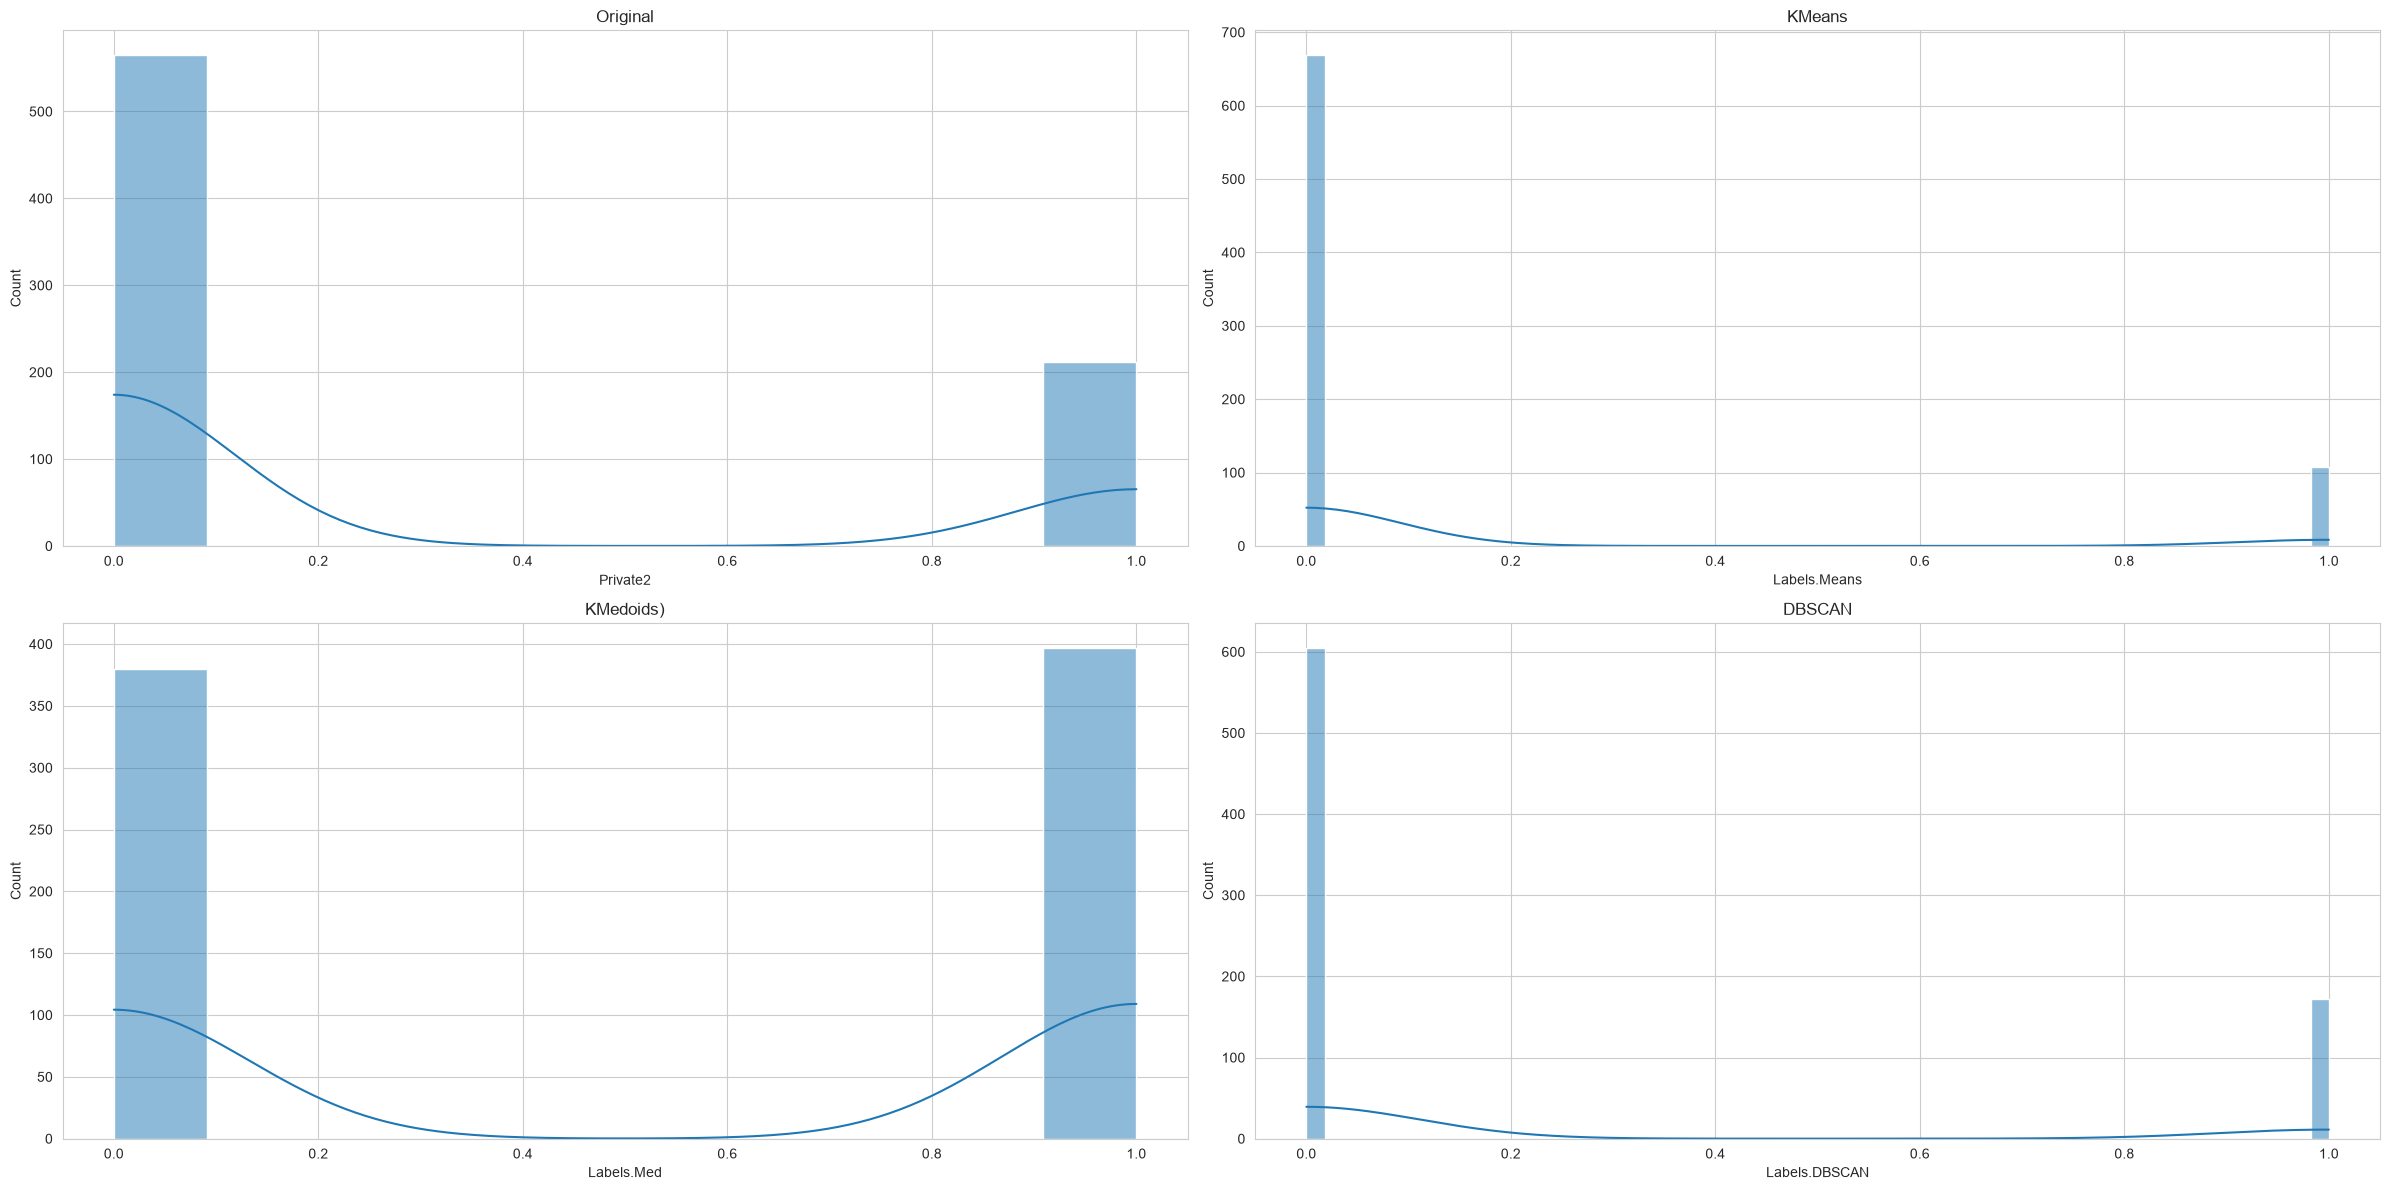

In [92]:
fig, axes = plt.subplots(2, 2, figsize=(24, 12))

sns.histplot(data=df, x='Private2', kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Original')

sns.histplot(data=df_means, x='Labels.Means', kde=True, ax=axes[0, 1])
axes[0, 1].set_title('KMeans')

sns.histplot(data=df_med, x='Labels.Med', kde=True, ax=axes[1, 0])
axes[1, 0].set_title('KMedoids)')

sns.histplot(data=df_db, x='Labels.DBSCAN', kde=True, ax=axes[1, 1])
axes[1, 1].set_title('DBSCAN')

plt.tight_layout()

In [93]:
print("Classification report")
print(f"DBSCAN: {classification_report(y, dbscan_labels, zero_division=0)}")
print(f"K-Means: {classification_report(y, kmeans_labels, zero_division=0)}\n")

Classification report
DBSCAN:               precision    recall  f1-score   support

          -1       0.00      0.00      0.00         0
           0       0.81      0.87      0.84       565
           1       0.00      0.00      0.00       212

    accuracy                           0.63       777
   macro avg       0.27      0.29      0.28       777
weighted avg       0.59      0.63      0.61       777

K-Means:               precision    recall  f1-score   support

           0       0.82      0.98      0.89       565
           1       0.88      0.42      0.57       212

    accuracy                           0.83       777
   macro avg       0.85      0.70      0.73       777
weighted avg       0.84      0.83      0.80       777




In [94]:
print("Homogeneity")
print(f"DBSCAN: {metrics.homogeneity_score(y, dbscan_labels):.3f}")
print(f"K-Means: {metrics.homogeneity_score(y, kmeans_labels):.3f}\n")

print("Completeness")
print(f"DBSCAN: {metrics.completeness_score(y, dbscan_labels):.3f}")
print(f"K-Means: {metrics.completeness_score(y, kmeans_labels):.3f}\n")

print("V-measure")
print(f"DBSCAN {metrics.v_measure_score(y, dbscan_labels):.3f}")
print(f"K-Means: {metrics.v_measure_score(y, kmeans_labels):.3f}\n")

print("Adjusted Rand Index")
print(f"DBSCAN: {metrics.adjusted_rand_score(y, dbscan_labels):.3f}")
print(f"K-Means: {metrics.adjusted_rand_score(y, kmeans_labels):.3f}\n")

print("Adjusted Mutual Information:")
print(f"DBSCAN: {metrics.adjusted_mutual_info_score(y, dbscan_labels):.3f}")
print(f"K-Means: {metrics.adjusted_mutual_info_score(y, kmeans_labels):.3f}\n")

Homogeneity
DBSCAN: 0.114
K-Means: 0.215

Completeness
DBSCAN: 0.119
K-Means: 0.326

V-measure
DBSCAN 0.117
K-Means: 0.259

Adjusted Rand Index
DBSCAN: 0.224
K-Means: 0.352

Adjusted Mutual Information:
DBSCAN: 0.115
K-Means: 0.258



**Which model performed better for this data set?**  
Outline a critical analysis of these three models.

#### Análise crítica
*(Confirmar com os valores obtidos ao correr o notebook.)*

- **Os dados não estão normalizados.** O K-Means, o K-Medoids e o DBSCAN usam distância euclidiana, por isso as variáveis com valores na ordem dos milhares (`Apps`, `Accept`, `F.Undergrad`, `Outstate`, `Expend`) dominam a distância. As percentagens (`Top10perc`, `PhD`, `Grad.Rate`) quase não contam. Os clusters acabam por separar universidades **grandes de pequenas**, e só indiretamente **privadas de públicas**. Normalizar os dados (por exemplo com `StandardScaler`) deve melhorar os três modelos.
- **K-Means:** é o mais adequado quando se sabe que há 2 grupos. Separa razoavelmente pelo tamanho e pelas propinas (`Outstate`), mas é sensível aos outliers (universidades muito grandes), que puxam os centróides.
- **K-Medoids:** os resultados devem ser semelhantes aos do K-Means. Como os centros são universidades reais, é **mais robusto aos outliers** e mais fácil de interpretar. Em troca, é mais lento.
- **DBSCAN:** é o menos adequado para este problema:
  - em 17 dimensões e sem normalização, a densidade é muito desigual (há poucas universidades públicas grandes);
  - por isso, ou junta quase tudo num cluster, ou marca muitas universidades como ruído;
  - não deixa escolher 2 grupos, e o resultado depende muito de `eps`.

  Mesmo assim, é útil para **detetar as universidades atípicas** (ruído = -1).
- **Conclusão:** o **K-Means / K-Medoids** é a melhor escolha para separar privadas de públicas, e deve ser usado sempre com os dados normalizados. As métricas sem labels (Silhouette) e com labels (ARI, AMI, V-measure) devem ser lidas em conjunto. A accuracy só faz sentido depois de alinhar os números dos clusters com as classes reais.